# Algoinst Pilot evaluation

In [1]:
import pandas as pd
import numpy as np
import ast
import seaborn as sns
import requests
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
url = "https://ai-inst-master.chm.mpib-berlin.mpg.de/get_csv?type=round"

local_filename = "all.csv"

response = requests.get(url)


with open(local_filename, "wb") as file:
    file.write(response.content)

In [3]:
# sessions = ["wwjoqsbe", "unc1fc2m",  "ka5v3qsi", "85dlorg9"]
# manager_map = {"wwjoqsbe":"ci, γ=1", "unc1fc2m":"ci, γ=1", "ka5v3qsi": "ci, γ=0.9", "85dlorg9": "pgh, γ=0.98"}
sessions = [
    "rzxe19eg",
    "fx4glgwj",
    "od6716ho",
    "7nki28wg",
    "hhl7yk2l",
    "2iu7mws9",
    "9uxydej0",
    "l4w1qzmz",
    "bzormoyg",
    "iowvzezr",
    "kes3nebx",
    "d9wukpqo",
    "wqehcexq",
]
# outlier_managers = ["3nylj27q", "ad53hfkv"] # Extreme negative common good
outlier_managers = []
# outlier_managers = ["3nylj27q","6fcfgla2","ad53hfkv","v1r8itbk","ysqk4y6b"] # Everyone with common good < 0

In [4]:
df = pd.read_csv(local_filename)

In [5]:
df = df[df["session"].isin(sessions) & (~df["manager_code"].isin(outlier_managers))]

In [6]:
df["session"].unique()

array(['rzxe19eg', 'fx4glgwj', 'od6716ho', '7nki28wg', 'hhl7yk2l',
       '2iu7mws9', '9uxydej0', 'l4w1qzmz', 'bzormoyg', 'iowvzezr',
       'kes3nebx', 'd9wukpqo', 'wqehcexq'], dtype=object)

In [7]:
df["manager_code"].nunique()

169

In [8]:
mdf = df.groupby("manager_code")["round"].max().reset_index()
broken_examples = list(mdf[mdf["round"] < 24]["manager_code"])
df = df[~df["manager_code"].isin(broken_examples)]

In [9]:
df["contributions"] = df["contributions"].apply(ast.literal_eval)
df["groups"] = df["groups"].apply(ast.literal_eval)
df["punishments"] = df["punishments"].apply(ast.literal_eval)
df["participant_codes"] = df["participant_codes"].apply(ast.literal_eval)
df["missing_inputs"] = df["missing_inputs"].apply(ast.literal_eval)

In [10]:
dfe = df.explode(
    ["participant_codes", "contributions", "punishments", "groups", "missing_inputs"]
)

In [11]:
dfe.loc[dfe["groups"] == "ai_governor", "manager"] = "ai_manager"

In [12]:
dfe.loc[dfe["groups"] == "human_governor", "manager"] = "human"

In [13]:
(df["manager_code"].value_counts() == 24).index

Index(['s9jhzi6t', 'reuk5n2a', 'yc8vtupt', 'ko7bjydp', 'a6pobzxl', '3nylj27q',
       'qfu1q61b', 'xs4512m8', 'blswhncw', 'tyk7twy6',
       ...
       '5q50jto9', 'voify0cm', '49f5unel', 'ouna17oi', 'dnnep8s9', 'iy8hu3un',
       'soaf15c7', 'lty9qdmz', 'jqve5wic', 'cy674dlo'],
      dtype='object', name='manager_code', length=167)

In [14]:
missing = dfe["missing_inputs"]
dfe[missing]["contributions"] = 0
dfe[missing]["punishments"] = 0

dfe["group_session"] = (
    dfe["groups"] + "_" + dfe["session"] + dfe["group_idx"].astype(str)
)
dfe["group_contributions"] = pd.to_numeric(
    dfe.groupby(["group_session", "round"])["contributions"].transform("sum")
)
dfe["group_punishments"] = pd.to_numeric(
    dfe.groupby(["group_session", "round"])["punishments"].transform("sum")
)
dfe["group_missing"] = pd.to_numeric(
    dfe.groupby(["group_session", "round"])["missing_inputs"].transform("sum")
)

dfe["common_good"] = dfe["group_contributions"] * 1.6 - dfe["group_punishments"]

dfe["payoff"] = (
    20
    - dfe["contributions"]
    - dfe["punishments"]
    + dfe["common_good"] / (4 - dfe["group_missing"])
)

dfe[missing]["payoff"] = 0

for mn in ["contributions", "punishments", "common_good", "payoff"]:
    dfe[mn] = pd.to_numeric(dfe[mn])
    dfe[f"{mn}_mean"] = dfe.groupby("group_session")[mn].transform("mean")

dfe["contribution_delta"] = dfe["contributions"] - dfe["contributions_mean"]
dfe["payoff_delta"] = dfe["payoff"] - dfe["payoff_mean"]
dfe["punishment_delta"] = dfe["punishments"] - dfe["punishments_mean"]

/tmp/ipykernel_26589/2251771192.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfe[missing]["contributions"] = 0
/tmp/ipykernel_26589/2251771192.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfe[missing]["punishments"] = 0
/tmp/ipykernel_26589/2251771192.py:27: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_gu

In [15]:
dfe

,id,revision_id,contributions,punishments,missing_inputs,missing_governor_input,groups,participant_codes,manager_code,manager_identity_transparent,...,group_missing,common_good,payoff,contributions_mean,punishments_mean,common_good_mean,payoff_mean,contribution_delta,payoff_delta,punishment_delta
1081,67361092c9ff6e96a53cf4b4,NaN,3,8,False,False,human_governor,t34uu5qc,s9jhzi6t,True,...,0,39.0,18.75,14.218750,2.072917,82.708333,24.385417,-11.218750,-5.635417,5.927083
1081,67361092c9ff6e96a53cf4b4,NaN,8,2,False,False,human_governor,g286gj0i,s9jhzi6t,True,...,0,39.0,19.75,14.218750,2.072917,82.708333,24.385417,-6.218750,-4.635417,-0.072917
1081,67361092c9ff6e96a53cf4b4,NaN,20,0,False,False,human_governor,yhvg4oxc,s9jhzi6t,True,...,0,39.0,9.75,14.218750,2.072917,82.708333,24.385417,5.781250,-14.635417,-2.072917
1081,67361092c9ff6e96a53cf4b4,NaN,4,7,False,False,human_governor,w7wup16f,s9jhzi6t,True,...,0,39.0,18.75,14.218750,2.072917,82.708333,24.385417,-10.218750,-5.635417,4.927083
1082,673610dfc9ff6e96a53cf4b5,NaN,9,4,False,False,human_governor,t34uu5qc,s9jhzi6t,True,...,0,30.2,14.55,14.218750,2.072917,82.708333,24.385417,-5.218750,-9.835417,1.927083
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5225,685acbd6c9ff6e96a53d07ea,NaN,6,3,False,False,human_governor,6qmfprhf,cy674dlo,False,...,0,10.4,13.60,6.302083,2.906250,28.708333,18.343750,-0.302083,-4.743750,0.093750
5226,685acc43c9ff6e96a53d07eb,NaN,3,1,False,False,human_governor,bsn29bfw,cy674dlo,False,...,0,16.4,20.10,6.302083,2.906250,28.708333,18.343750,-3.302083,1.756250,-1.906250
5226,685acc43c9ff6e96a53d07eb,NaN,4,2,False,False,human_governor,a18llvpv,cy674dlo,False,...,0,16.4,18.10,6.302083,2.906250,28.708333,18.343750,-2.302083,-0.243750,-0.906250
5226,685acc43c9ff6e96a53d07eb,NaN,0,0,False,False,human_governor,mqltrn2p,cy674dlo,False,...,0,16.4,24.10,6.302083,2.906250,28.708333,18.343750,-6.302083,5.756250,-2.906250


In [16]:
dfe["condition"] = dfe["groups"] + dfe["manager_identity_transparent"].apply(
    lambda x: "_transparent" if x else "_opaque"
)

In [17]:
top_40_sessions = []
for condition, dfc in dfe.groupby("condition"):
    print(condition, dfc["group_session"].nunique())
    top_40_sessions.extend(list(dfc["group_session"].unique())[:40])

ai_governor_opaque 41
ai_governor_transparent 43
human_governor_opaque 42
human_governor_transparent 41


In [18]:
dfe = dfe[dfe["group_session"].isin(top_40_sessions)]

for condition, dfc in dfe.groupby("condition"):
    print(condition, dfc["group_session"].nunique())
    top_40_sessions.extend(list(dfc["group_session"].unique())[:40])

ai_governor_opaque 40
ai_governor_transparent 40
human_governor_opaque 40
human_governor_transparent 40


In [19]:
dfe["condition"].unique()

array(['human_governor_transparent', 'human_governor_opaque',
       'ai_governor_transparent', 'ai_governor_opaque'], dtype=object)

In [20]:
len(dfe["group_session"].unique())

160

In [21]:
# dfmg = dfe[dfe["manager_code"].isin(outlier_managers)].groupby(["manager_code", "round"])[["payoff", "punishments"]].mean().reset_index()
dfmg = (
    dfe[dfe["manager"] == "human"]
    .groupby(["manager_code", "round"])[["payoff", "punishments"]]
    .mean()
    .reset_index()
)

In [22]:
palette = {
    x: "orange" if x in outlier_managers else "lightblue"
    for x in dfmg["manager_code"].unique()
}
palette["3nylj27q"] = "darkorange"

In [23]:
dfgr = dfmg.groupby("manager_code").sum()

/tmp/ipykernel_26589/3127594424.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=dfgr, x="manager_code", y="payoff", palette=palette)


([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38,
  39,
  40,
  41,
  42,
  43,
  44,
  45,
  46,
  47,
  48,
  49,
  50,
  51,
  52,
  53,
  54,
  55,
  56,
  57,
  58,
  59,
  60,
  61,
  62,
  63,
  64,
  65,
  66,
  67,
  68,
  69,
  70,
  71,
  72,
  73,
  74,
  75,
  76,
  77,
  78,
  79],
 [Text(0, 0, '23te8b18'),
  Text(1, 0, '2e06duha'),
  Text(2, 0, '2kz6bqfk'),
  Text(3, 0, '2rexmpfi'),
  Text(4, 0, '2x66txo2'),
  Text(5, 0, '2zvj293g'),
  Text(6, 0, '3nylj27q'),
  Text(7, 0, '3zzdqsdk'),
  Text(8, 0, '49f5unel'),
  Text(9, 0, '4szrt00i'),
  Text(10, 0, '4ugc0uq8'),
  Text(11, 0, '4vuokay2'),
  Text(12, 0, '53pnze13'),
  Text(13, 0, '558wij23'),
  Text(14, 0, '5cdleeaq'),
  Text(15, 0, '5k442l75'),
  Text(16, 0, '5q50jto9'),
  Text(17, 0, '5r2t9mj9'),
  Text(18, 0, '6fcfgla2'),
  Text(19, 0, '7mrte7vj'),

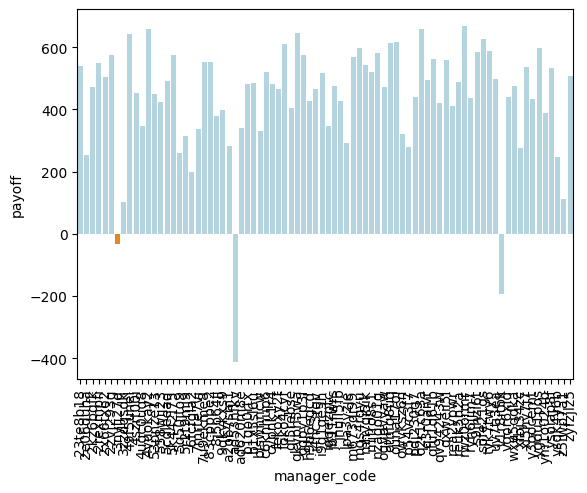

In [24]:
sns.barplot(data=dfgr, x="manager_code", y="payoff", palette=palette)
plt.xticks(rotation=90)

In [25]:
dfe[dfe["manager"] == "human"]["punishments"].mean()

np.float64(3.8002604166666667)

In [26]:
dfpgh = dfe[dfe["manager"] == "pgh, γ=0.98"]

In [27]:
dfpgh.groupby(["group_session"])["payoff"].mean().reset_index()["payoff"].std()

nan

In [28]:
dfpgh["punishments"].mean()

nan

# Evaluation of contribution in human and AI groups

Group ai_governor_ka5v3qsi2 stands out as the only group with contributions converging to everyone at 20.

<Axes: xlabel='round', ylabel='contributions'>

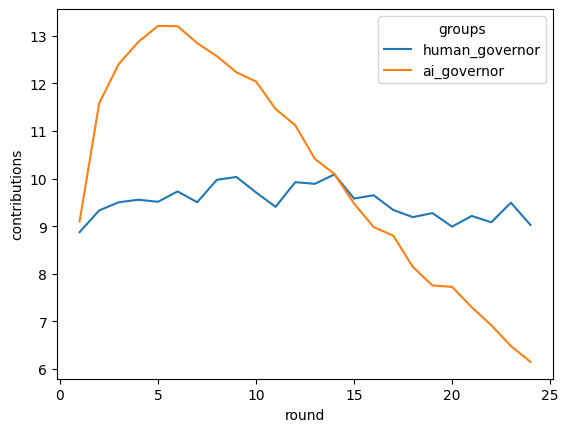

In [29]:
sns.lineplot(data=dfe, x="round", y="contributions", hue="groups", errorbar=None)

<Axes: xlabel='round', ylabel='common_good'>

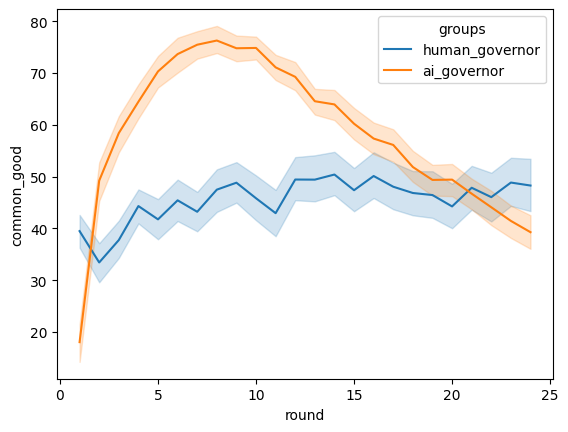

In [30]:
sns.lineplot(data=dfe, x="round", y="common_good", hue="groups")

In [31]:
dfe.reset_index(inplace=True)

<Axes: xlabel='round', ylabel='punishments'>

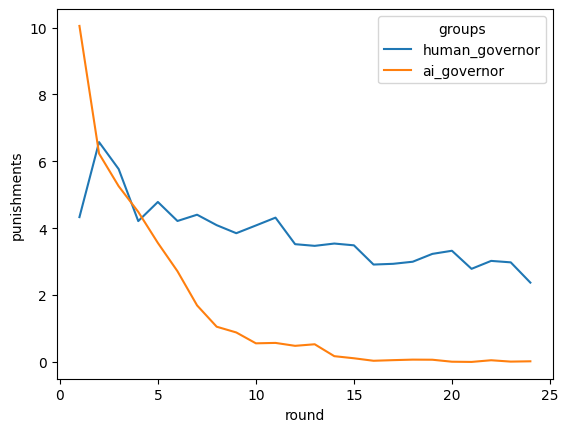

In [32]:
sns.lineplot(data=dfe, x="round", y="punishments", hue="groups", errorbar=None)

But also on average are the contributions and the common good are higher for the ai governor.

# Payoffs

In [33]:
dfe

,index,id,revision_id,contributions,punishments,missing_inputs,missing_governor_input,groups,participant_codes,manager_code,...,common_good,payoff,contributions_mean,punishments_mean,common_good_mean,payoff_mean,contribution_delta,payoff_delta,punishment_delta,condition
0,1081,67361092c9ff6e96a53cf4b4,NaN,3,8,False,False,human_governor,t34uu5qc,s9jhzi6t,...,39.0,18.75,14.218750,2.072917,82.708333,24.385417,-11.218750,-5.635417,5.927083,human_governor_transparent
1,1081,67361092c9ff6e96a53cf4b4,NaN,8,2,False,False,human_governor,g286gj0i,s9jhzi6t,...,39.0,19.75,14.218750,2.072917,82.708333,24.385417,-6.218750,-4.635417,-0.072917,human_governor_transparent
2,1081,67361092c9ff6e96a53cf4b4,NaN,20,0,False,False,human_governor,yhvg4oxc,s9jhzi6t,...,39.0,9.75,14.218750,2.072917,82.708333,24.385417,5.781250,-14.635417,-2.072917,human_governor_transparent
3,1081,67361092c9ff6e96a53cf4b4,NaN,4,7,False,False,human_governor,w7wup16f,s9jhzi6t,...,39.0,18.75,14.218750,2.072917,82.708333,24.385417,-10.218750,-5.635417,4.927083,human_governor_transparent
4,1082,673610dfc9ff6e96a53cf4b5,NaN,9,4,False,False,human_governor,t34uu5qc,s9jhzi6t,...,30.2,14.55,14.218750,2.072917,82.708333,24.385417,-5.218750,-9.835417,1.927083,human_governor_transparent
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15355,5172,685abd9bc9ff6e96a53d079e,NaN,8,0,False,False,ai_governor,b8zoi006,dnnep8s9,...,19.2,16.80,10.583333,0.843750,64.358333,24.851389,-2.583333,-8.051389,-0.843750,ai_governor_opaque
15356,5176,685abde9c9ff6e96a53d07a7,NaN,1,0,False,False,ai_governor,a3zzaz6d,dnnep8s9,...,17.6,23.40,10.583333,0.843750,64.358333,24.851389,-9.583333,-1.451389,-0.843750,ai_governor_opaque
15357,5176,685abde9c9ff6e96a53d07a7,NaN,2,0,False,False,ai_governor,af3a644m,dnnep8s9,...,17.6,22.40,10.583333,0.843750,64.358333,24.851389,-8.583333,-2.451389,-0.843750,ai_governor_opaque
15358,5176,685abde9c9ff6e96a53d07a7,NaN,0,0,False,False,ai_governor,3p1sbazq,dnnep8s9,...,17.6,24.40,10.583333,0.843750,64.358333,24.851389,-10.583333,-0.451389,-0.843750,ai_governor_opaque


<Axes: xlabel='round', ylabel='common_good'>

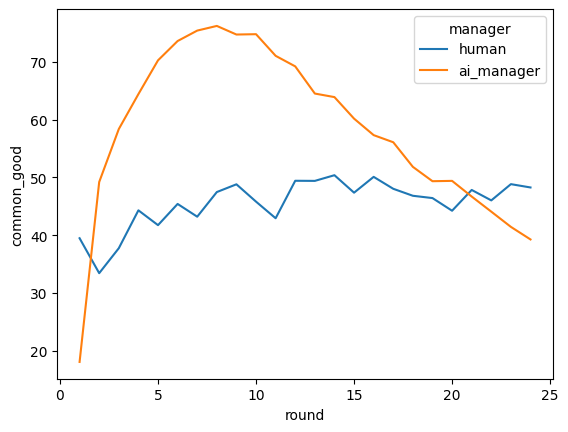

In [34]:
sns.lineplot(data=dfe, x="round", y="common_good", hue="manager", errorbar=None)

Only ai_governor_ka5v3qsi2 consistently produces higher payoffs than the human groups

<Axes: xlabel='round', ylabel='payoff'>

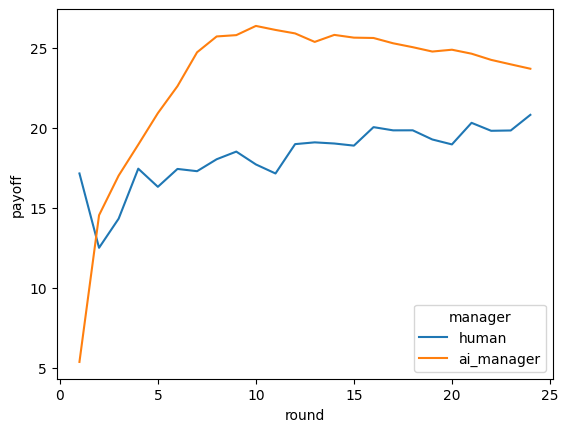

In [35]:
sns.lineplot(data=dfe, x="round", y="payoff", hue="manager", errorbar=None)

In [36]:
dfe.groupby(["manager", "group_session"])["payoff"].sum().reset_index().groupby(
    ["manager"]
)["payoff"].mean()

manager
ai_manager    2211.906667
human         1754.378333
Name: payoff, dtype: float64

In [37]:
dfe.groupby(["manager"])["common_good"].mean()

manager
ai_manager    58.331875
human         45.568125
Name: common_good, dtype: float64

In [38]:
dfe.groupby(["manager"])["contributions"].mean()

manager
ai_manager    10.120703
human          9.495182
Name: contributions, dtype: float64

In [39]:
dfe.groupby(["manager"])["payoff"].mean()

manager
ai_manager    23.040694
human         18.274774
Name: payoff, dtype: float64

In [40]:
dfs = (
    dfe.groupby(["group_session", "manager", "manager_identity_transparent"])
    .mean(numeric_only=True)
    .reset_index()
)

([0, 1], [Text(0, 0, 'ai_manager'), Text(1, 0, 'human')])

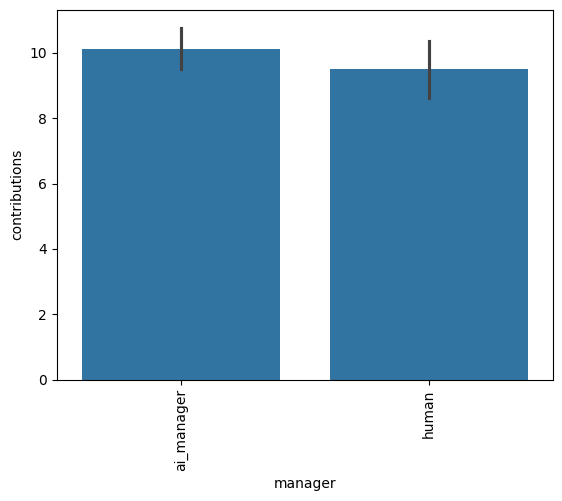

In [41]:
sns.barplot(data=dfs, x="manager", y="contributions")
plt.xticks(rotation=90)

([0, 1], [Text(0, 0, 'ai_manager'), Text(1, 0, 'human')])

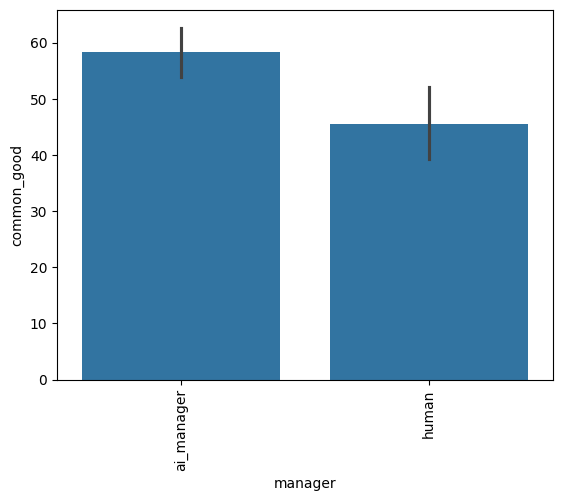

In [42]:
sns.barplot(data=dfs, x="manager", y="common_good")
plt.xticks(rotation=90)

In [43]:
dfe[dfe["round"] < 8].groupby(["manager"])["payoff"].mean()

manager
ai_manager    17.731101
human         16.065208
Name: payoff, dtype: float64

In [44]:
np.std(np.array(dfs[dfs["manager"] == "pgh, γ=0.98"]["payoff"]))

/home/capablanc/miniforge3/envs/algoinst/lib/python3.10/site-packages/numpy/_core/_methods.py:223: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/capablanc/miniforge3/envs/algoinst/lib/python3.10/site-packages/numpy/_core/_methods.py:181: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/home/capablanc/miniforge3/envs/algoinst/lib/python3.10/site-packages/numpy/_core/_methods.py:215: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


np.float64(nan)

In [45]:
dfs = dfs.sort_values("manager", ascending=True)
dfs

,group_session,manager,manager_identity_transparent,index,revision_id,contributions,punishments,missing_governor_input,group_idx,round,...,group_missing,common_good,payoff,contributions_mean,punishments_mean,common_good_mean,payoff_mean,contribution_delta,payoff_delta,punishment_delta
0,ai_governor_2iu7mws912,ai_manager,False,2861.500000,NaN,7.375000,2.229167,0.000000,12.0,12.5,...,0.125000,38.283333,20.277778,7.375000,2.229167,38.283333,20.277778,0.000000e+00,-3.700743e-17,1.480297e-16
57,ai_governor_kes3nebx6,ai_manager,True,4265.666667,NaN,7.416667,1.093750,0.000000,6.0,12.5,...,0.041667,43.091667,22.456944,7.416667,1.093750,43.091667,22.456944,-3.145632e-16,-4.070818e-16,0.000000e+00
56,ai_governor_kes3nebx4,ai_manager,True,4216.125000,NaN,6.041667,0.718750,0.000000,4.0,12.5,...,0.000000,35.791667,22.187500,6.041667,0.718750,35.791667,22.187500,-4.810966e-16,5.921189e-16,0.000000e+00
55,ai_governor_kes3nebx2,ai_manager,False,4190.666667,NaN,13.312500,1.114583,0.000000,2.0,12.5,...,0.083333,80.741667,26.219444,13.312500,1.114583,80.741667,26.219444,0.000000e+00,7.401487e-16,8.326673e-17
54,ai_governor_kes3nebx11,ai_manager,True,4346.333333,NaN,11.260417,1.385417,0.000000,11.0,12.5,...,0.000000,66.525000,23.985417,11.260417,1.385417,66.525000,23.985417,5.921189e-16,2.035409e-15,-8.789266e-17
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102,human_governor_d9wukpqo18,human,False,4787.833333,NaN,15.427083,3.187500,0.000000,18.0,12.5,...,0.208333,85.983333,23.760417,15.427083,3.187500,85.983333,23.760417,-5.921189e-16,3.700743e-17,0.000000e+00
101,human_governor_d9wukpqo17,human,True,4765.083333,NaN,14.197917,2.145833,0.000000,17.0,12.5,...,0.000000,82.283333,24.227083,14.197917,2.145833,82.283333,24.227083,5.921189e-16,-2.035409e-15,-7.401487e-17
99,human_governor_d9wukpqo11,human,True,4632.041667,NaN,2.395833,2.260417,0.000000,11.0,12.5,...,0.041667,6.291667,16.912500,2.395833,2.260417,6.291667,16.912500,-1.665335e-16,2.238950e-15,1.850372e-16
118,human_governor_iowvzezr12,human,False,3829.625000,NaN,3.906250,1.479167,0.041667,12.0,12.5,...,0.125000,19.083333,19.415278,3.906250,1.479167,19.083333,19.415278,0.000000e+00,5.181041e-16,-4.394633e-17


([0, 1], [Text(0, 0, 'ai_manager'), Text(1, 0, 'human')])

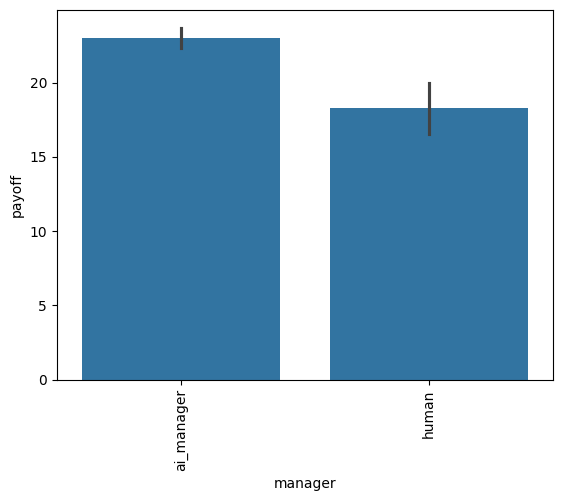

In [46]:
sns.barplot(data=dfs, x="manager", y="payoff", errorbar=("se", 2))
plt.xticks(rotation=90)

In [98]:
sns.barplot(data=dfs, x="group_session", y="payoff", errorbar=("se", 2))

ValueError: Could not interpret value `payoff` for `y`. An entry with this name does not appear in `data`.

## Transparent condition analysis


([0, 1, 2, 3],
 [Text(0, 0, 'ai_governor_opaque'),
  Text(1, 0, 'ai_governor_transparent'),
  Text(2, 0, 'human_governor_transparent'),
  Text(3, 0, 'human_governor_opaque')])

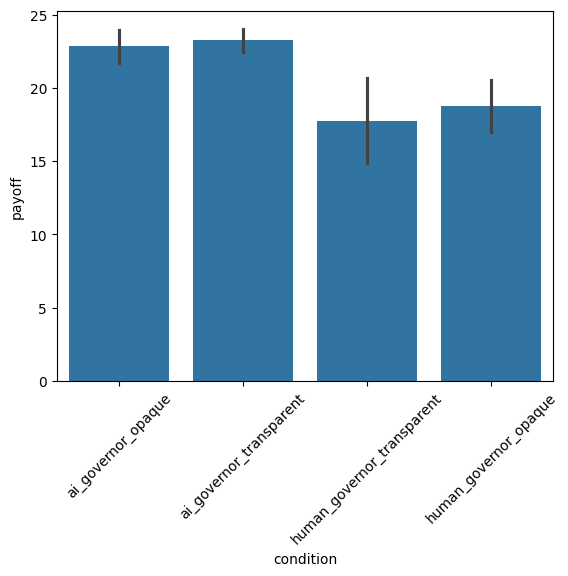

In [47]:
dft = (
    dfe.groupby(["group_session", "condition", "manager_identity_transparent"])
    .mean(numeric_only=True)
    .reset_index()
)
sns.barplot(data=dft, x="condition", y="payoff", errorbar=("se", 2))
plt.xticks(rotation=45)

<Axes: xlabel='manager_identity_transparent', ylabel='payoff'>

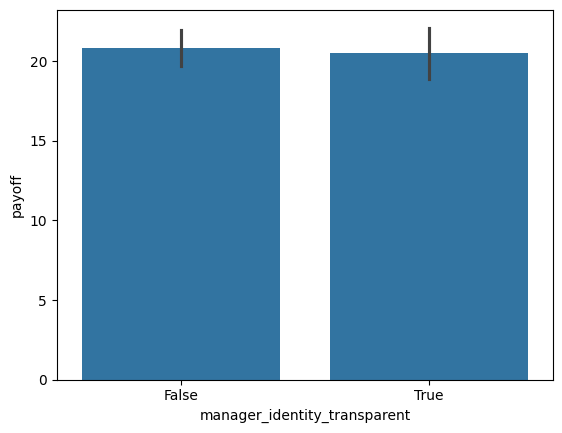

In [48]:
sns.barplot(data=dft, x="manager_identity_transparent", y="payoff", errorbar=("se", 2))

In [49]:
dfe8 = dfe[dfe["round"] <= 8]
dfs8 = (
    dfe8.groupby(["group_session", "manager", "manager_identity_transparent"])
    .mean(numeric_only=True)
    .reset_index()
)

In [50]:
dfs8 = dfs8.sort_values("manager", ascending=True)

([0, 1], [Text(0, 0, 'ai_manager'), Text(1, 0, 'human')])

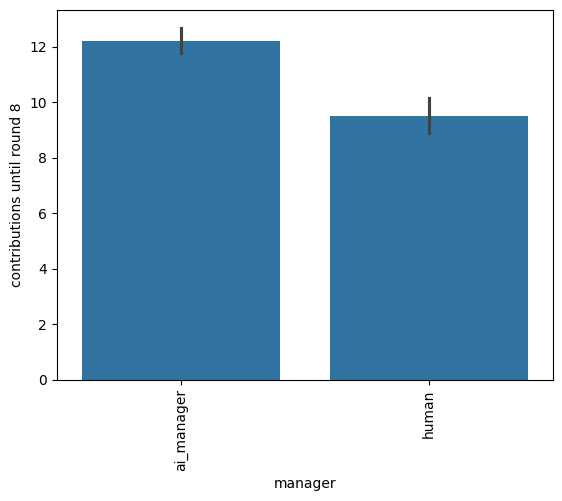

In [51]:
sns.barplot(data=dfs8, x="manager", y="contributions")
plt.ylabel("contributions until round 8")
plt.xticks(rotation=90)

([0, 1], [Text(0, 0, 'ai_manager'), Text(1, 0, 'human')])

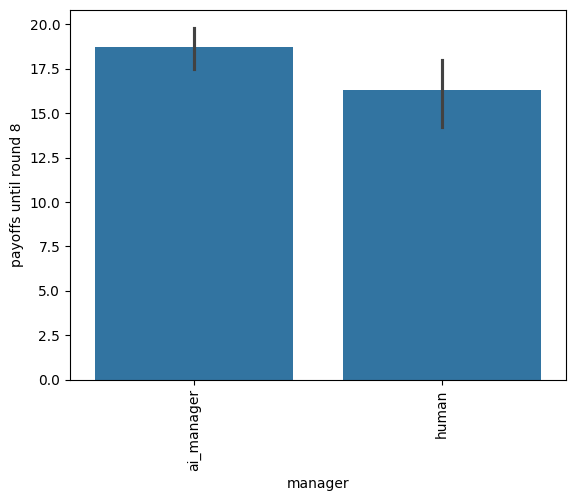

In [52]:
sns.barplot(data=dfs8, x="manager", y="payoff")
plt.ylabel("payoffs until round 8")
plt.xticks(rotation=90)

([0, 1], [Text(0, 0, 'ai_manager'), Text(1, 0, 'human')])

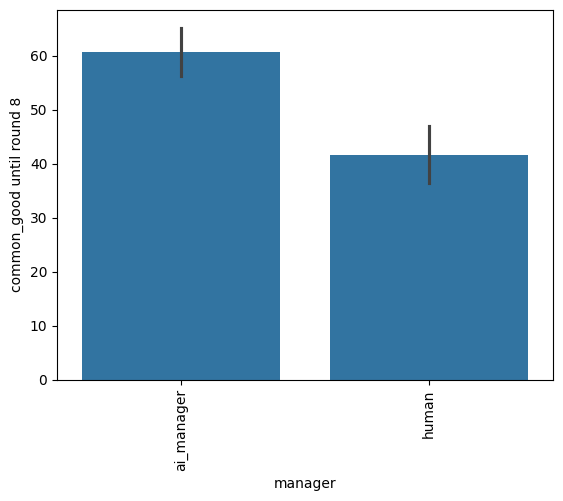

In [53]:
sns.barplot(data=dfs8, x="manager", y="common_good")
plt.ylabel("common_good until round 8")
plt.xticks(rotation=90)

In [54]:
dfc = (
    dfe.groupby(["manager"])[["contributions", "punishments"]]
    .corr("pearson")
    .reset_index()
)
dfc = dfc[dfc["level_1"] == "contributions"][["manager", "punishments"]].rename(
    columns={"punishments": "pearson_corr_between_contribution_and_punishment"}
)
dfc

,manager,pearson_corr_between_contribution_and_punishment
0,ai_manager,-0.250931
2,human,-0.183144


In [55]:
dfc = (
    dfe.groupby(["manager"])[["contributions", "punishments"]]
    .corr("spearman")
    .reset_index()
)
dfc = dfc[dfc["level_1"] == "contributions"][["manager", "punishments"]].rename(
    columns={"punishments": "pearson_corr_between_contribution_and_punishment"}
)
dfc

,manager,pearson_corr_between_contribution_and_punishment
0,ai_manager,0.016522
2,human,-0.258586


(array([], dtype=float64), [])

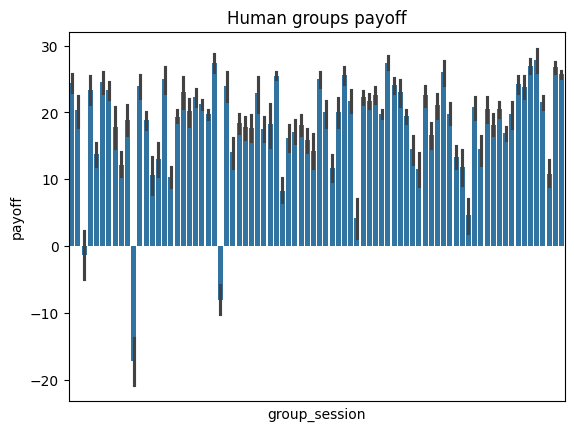

In [100]:
sns.barplot(data=dfe[dfe["manager"] == "human"], x="group_session", y="payoff")
plt.title("Human groups payoff")
plt.xticks([], [])
plt.xticks(rotation=90)

(array([], dtype=float64), [])

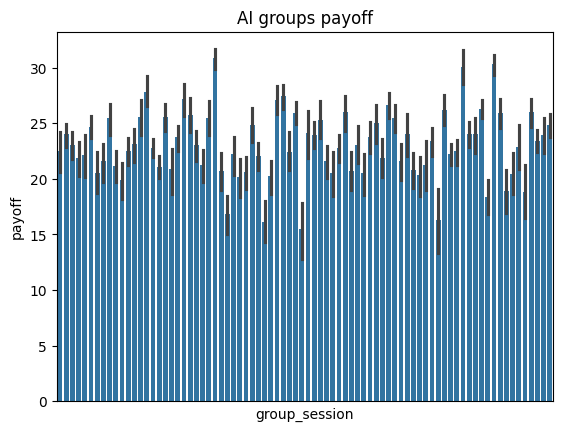

In [99]:
sns.barplot(data=dfe[dfe["manager"] == "ai_manager"], x="group_session", y="payoff")
plt.title("AI groups payoff")
plt.xticks([], [])
plt.xticks(rotation=90)

In [122]:
dfe["missing_inputs"] = dfe["missing_inputs"].astype(bool)

In [123]:
dfn = dfe[~dfe["missing_inputs"]]
algo_mean = dfn[dfn["manager"] == "ai_manager"]["payoff"].mean()
algo_mean

np.float64(22.908913502109705)

In [ ]:
dfn.columns

Index(['index', 'id', 'revision_id', 'contributions', 'punishments',
       'missing_inputs', 'missing_governor_input', 'groups',
       'participant_codes', 'manager_code', 'manager_identity_transparent',
       'human_manager_first', 'institution_chosen', 'group_idx', 'round',
       'session', 'all_models', 'add_punishments_runtime', 'datetime',
       'manager', 'group_session', 'group_contributions', 'group_punishments',
       'group_missing', 'common_good', 'payoff', 'contributions_mean',
       'punishments_mean', 'common_good_mean', 'payoff_mean',
       'contribution_delta', 'payoff_delta', 'punishment_delta', 'condition',
       'contribution_delta_binned'],
      dtype='object')

In [129]:
dfh = dfn[dfn["manager"] == "human"]
dfh = dfh[["group_session", "payoff"]]
dfhg = dfh.groupby("group_session").mean().reset_index()
dfhg["greater_than_ai_mean"] = dfhg["payoff"] > algo_mean
dfhg["smaller_than_ai_mean"] = dfhg["payoff"] < algo_mean

print(dfhg["greater_than_ai_mean"].sum(), dfhg["smaller_than_ai_mean"].sum(), len(dfhg))

21 59 80


In [125]:
dfn

,index,id,revision_id,contributions,punishments,missing_inputs,missing_governor_input,groups,participant_codes,manager_code,...,payoff,contributions_mean,punishments_mean,common_good_mean,payoff_mean,contribution_delta,payoff_delta,punishment_delta,condition,contribution_delta_binned
6268,2785,67d2e24ac9ff6e96a53cfc8e,NaN,0,0,False,False,ai_governor,w3ky0c19,9clbxr2v,...,44.000000,6.760417,3.958333,27.433333,16.139583,-6.760417,27.860417,-3.958333,ai_governor_opaque,-6.0
4798,2295,67649767c9ff6e96a53cfa4d,NaN,0,0,False,True,human_governor,foovou00,2zvj293g,...,42.000000,17.729167,3.885417,97.925000,23.926389,-17.729167,18.073611,-3.885417,human_governor_opaque,-12.5
15135,5051,685ab90ac9ff6e96a53d06fd,NaN,0,0,False,False,human_governor,61sa9rof,rwz0ormr,...,41.333333,16.343750,1.895833,97.016667,27.847917,-16.343750,13.485417,-1.895833,human_governor_opaque,-12.5
12582,4364,68556b07c9ff6e96a53d03e2,NaN,0,0,False,False,ai_governor,vy3d18la,hkel34o1,...,41.333333,16.541667,0.687500,103.116667,30.050000,-16.541667,11.283333,-0.687500,ai_governor_opaque,-12.5
3050,1858,6764631ac9ff6e96a53cf840,NaN,2,0,False,False,ai_governor,60ooyg01,8h64mzs3,...,41.200000,14.114583,0.625000,87.833333,27.784028,-12.114583,13.415972,-0.625000,ai_governor_transparent,-12.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2015,1599,673b78dec9ff6e96a53cf719,NaN,14,27,False,False,human_governor,7jvqmm82,ad53hfkv,...,-36.866667,7.250000,20.010417,-33.641667,-17.163194,6.750000,-19.703472,6.989583,human_governor_transparent,6.0
1980,1591,673b7668c9ff6e96a53cf711,NaN,19,22,False,False,human_governor,4e70mrhx,ad53hfkv,...,-38.800000,7.250000,20.010417,-33.641667,-17.163194,11.750000,-21.636806,1.989583,human_governor_transparent,12.5
2178,1640,67645876c9ff6e96a53cf747,NaN,15,30,False,False,human_governor,paxxynxd,2e06duha,...,-40.400000,13.395833,8.864583,50.275000,10.608333,1.604167,-51.008333,21.135417,human_governor_opaque,2.0
2522,1726,67645bd6c9ff6e96a53cf79d,NaN,20,30,False,False,human_governor,egt0dbaw,5r2t9mj9,...,-41.700000,3.791667,4.593750,5.891667,13.087500,16.208333,-54.787500,25.406250,human_governor_opaque,12.5


(array([], dtype=float64), [])

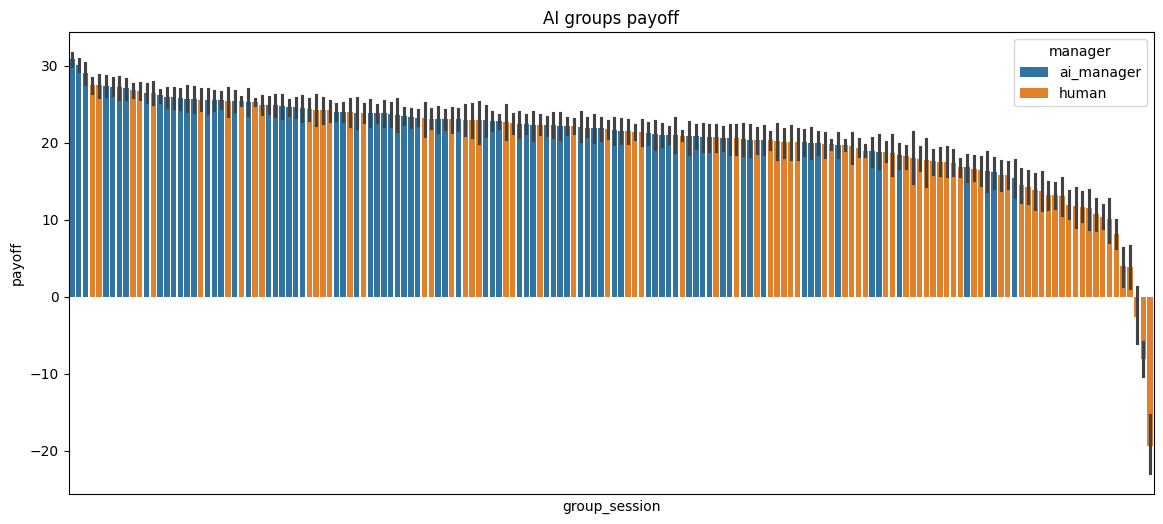

In [124]:
plt.figure(figsize=(14, 6))
dfn = dfn.sort_values("payoff", ascending=False)
order = dfn.groupby("group_session")["payoff"].mean().sort_values(ascending=False).index
sns.barplot(data=dfn, x="group_session", y="payoff", hue="manager", order=order)
plt.title("AI groups payoff")
plt.xticks([], [])
plt.xticks(rotation=90)

Indeed, the mean payoffs are lower for most of the ai_governor groups than for the human groups.

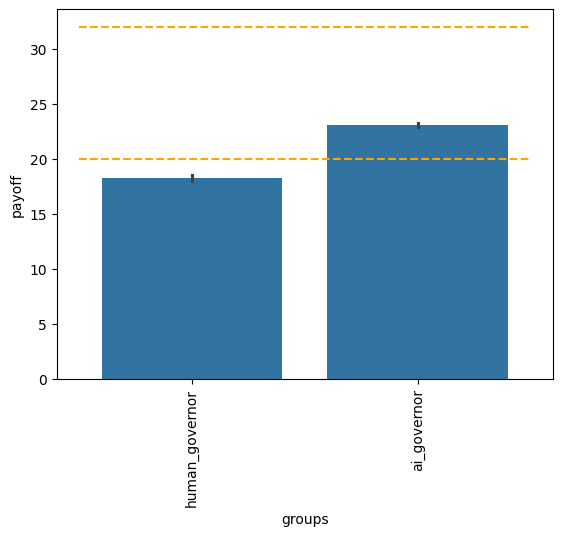

In [58]:
sns.barplot(data=dfe, x="groups", y="payoff")
plt.xticks(rotation=90)
plt.hlines(20, -0.5, 1.5, colors="orange", linestyles="dashed")
plt.hlines(32, -0.5, 1.5, colors="orange", linestyles="dashed")

In [59]:
mean_df = dfe.groupby("manager_code")[["common_good"]].mean()
mean_df[mean_df["common_good"] < 0]

,common_good
manager_code,
3nylj27q,-7.391667
6fcfgla2,-4.075000
ad53hfkv,-33.641667
v1r8itbk,-10.516667
ysqk4y6b,-2.016667


As seen in the following, this is despite the ai_governor groups achieving significantly higher common good

(array([], dtype=float64), [])

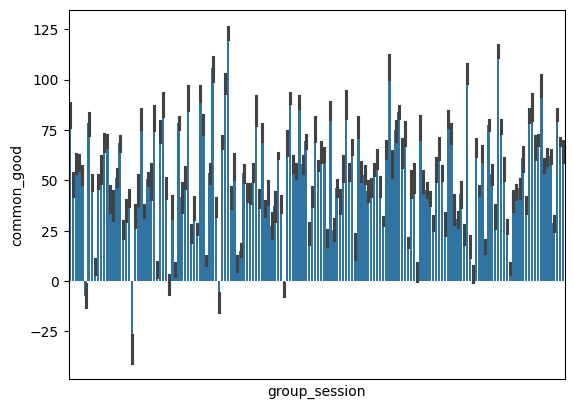

In [60]:
sns.barplot(data=dfe, x="group_session", y="common_good")
plt.xticks([], [])
plt.xticks(rotation=90)

([0, 1], [Text(0, 0, 'human_governor'), Text(1, 0, 'ai_governor')])

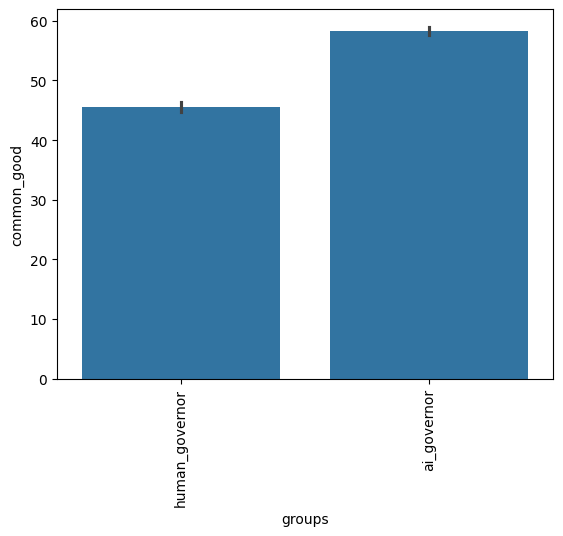

In [61]:
sns.barplot(data=dfe, x="groups", y="common_good")
plt.xticks(rotation=90)

In the later rounds, payoffs seem to be higher in the ai groups. Could we get to payoffs higher than the human groups by increasing the number of rounds to 24? Let's check the trend of the payoff cumsums for this.

In [62]:
dfs = dfe.sort_values(["group_session", "participant_codes", "round"]).reset_index(
    drop=True
)

In [63]:
dfs["payoff_cumsum"] = dfs.groupby(["group_session", "participant_codes"])[
    ["payoff"]
].cumsum()

(array([-5.,  0.,  5., 10., 15., 20., 25., 30.]),
 [Text(-5.0, 0, '−5'),
  Text(0.0, 0, '0'),
  Text(5.0, 0, '5'),
  Text(10.0, 0, '10'),
  Text(15.0, 0, '15'),
  Text(20.0, 0, '20'),
  Text(25.0, 0, '25'),
  Text(30.0, 0, '30')])

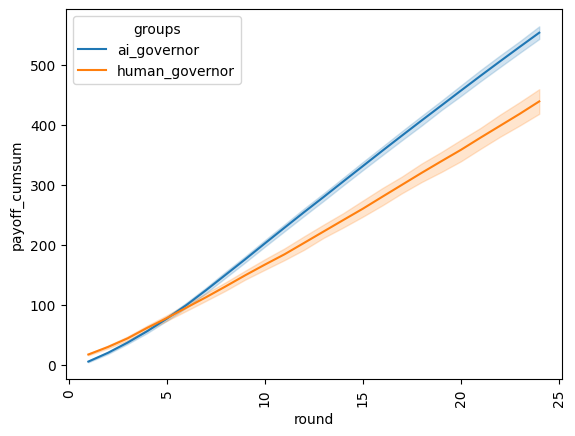

In [64]:
sns.lineplot(data=dfs, x="round", y="payoff_cumsum", hue="groups")
plt.xticks(rotation=90)

Nope does not seem like the lines would cross if we go to 24 rounds.

(array([-5.,  0.,  5., 10., 15., 20., 25., 30.]),
 [Text(-5.0, 0, '−5'),
  Text(0.0, 0, '0'),
  Text(5.0, 0, '5'),
  Text(10.0, 0, '10'),
  Text(15.0, 0, '15'),
  Text(20.0, 0, '20'),
  Text(25.0, 0, '25'),
  Text(30.0, 0, '30')])

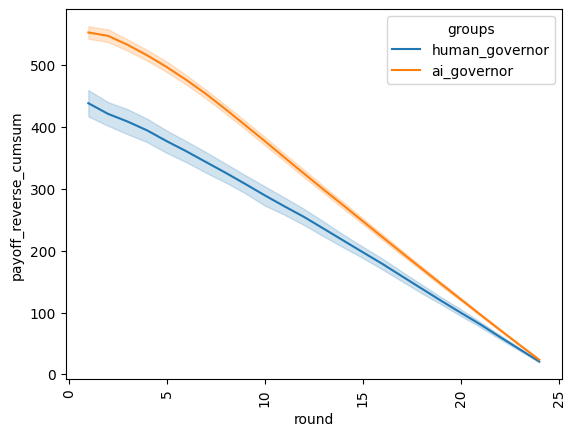

In [65]:
df_reverse = dfe.sort_values(
    ["group_session", "participant_codes", "round"], ascending=False
).reset_index(drop=True)
df_reverse["payoff_reverse_cumsum"] = df_reverse.groupby(
    ["group_session", "participant_codes"]
)[["payoff"]].cumsum()
sns.lineplot(data=df_reverse, x="round", y="payoff_reverse_cumsum", hue="groups")
plt.xticks(rotation=90)

# Cui bono?
Let's find out which types of participants profit in each condition.

In [66]:
dfm = dfe.melt(
    id_vars=["group_session", "round", "participant_codes", "groups", "manager"],
    value_vars=[
        "punishments",
        "contributions",
        "common_good",
        "payoff",
        "missing_inputs",
    ],
)
dfm

,group_session,round,participant_codes,groups,manager,variable,value
0,human_governor_rzxe19eg2,1,t34uu5qc,human_governor,human,punishments,8
1,human_governor_rzxe19eg2,1,g286gj0i,human_governor,human,punishments,2
2,human_governor_rzxe19eg2,1,yhvg4oxc,human_governor,human,punishments,0
3,human_governor_rzxe19eg2,1,w7wup16f,human_governor,human,punishments,7
4,human_governor_rzxe19eg2,2,t34uu5qc,human_governor,human,punishments,4
...,...,...,...,...,...,...,...
76795,ai_governor_wqehcexq11,23,b8zoi006,ai_governor,ai_manager,missing_inputs,False
76796,ai_governor_wqehcexq11,24,a3zzaz6d,ai_governor,ai_manager,missing_inputs,False
76797,ai_governor_wqehcexq11,24,af3a644m,ai_governor,ai_manager,missing_inputs,False
76798,ai_governor_wqehcexq11,24,3p1sbazq,ai_governor,ai_manager,missing_inputs,False


In [67]:
dfs = (
    dfm.groupby(["group_session", "participant_codes", "groups", "variable", "manager"])
    .sum()
    .reset_index()
)
dfs

,group_session,participant_codes,groups,variable,manager,round,value
0,ai_governor_2iu7mws912,8py29n8y,ai_governor,common_good,ai_manager,300,918.8
1,ai_governor_2iu7mws912,8py29n8y,ai_governor,contributions,ai_manager,300,204
2,ai_governor_2iu7mws912,8py29n8y,ai_governor,missing_inputs,ai_manager,300,0
3,ai_governor_2iu7mws912,8py29n8y,ai_governor,payoff,ai_manager,300,490.166667
4,ai_governor_2iu7mws912,8py29n8y,ai_governor,punishments,ai_manager,300,23
...,...,...,...,...,...,...,...
3195,human_governor_wqehcexq9,rtw5tfv5,human_governor,common_good,human,300,1985.2
3196,human_governor_wqehcexq9,rtw5tfv5,human_governor,contributions,human,300,336
3197,human_governor_wqehcexq9,rtw5tfv5,human_governor,missing_inputs,human,300,0
3198,human_governor_wqehcexq9,rtw5tfv5,human_governor,payoff,human,300,639.3


In [68]:
df_big = (
    dfs[dfs["variable"] == "contributions"]
    .merge(
        dfs[dfs["variable"] == "payoff"],
        on=["group_session", "participant_codes", "groups"],
    )
    .merge(
        dfs[dfs["variable"] == "punishments"],
        on=["group_session", "participant_codes", "groups"],
    )
    .rename(
        columns={"value_x": "contribution", "value_y": "payoff", "value": "punishment"}
    )
    .drop(
        columns=["variable_x", "variable_y", "variable", "round_x", "round_y", "round"]
    )
)

In [69]:
for numeric in ["contribution", "punishment", "payoff"]:
    df_big[numeric] = pd.to_numeric(df_big[numeric])

In [70]:
df_big

,group_session,participant_codes,groups,manager_x,contribution,manager_y,payoff,manager,punishment
0,ai_governor_2iu7mws912,8py29n8y,ai_governor,ai_manager,204,ai_manager,490.166667,ai_manager,23
1,ai_governor_2iu7mws912,wnsy7omt,ai_governor,ai_manager,162,ai_manager,490.166667,ai_manager,65
2,ai_governor_2iu7mws912,yj6u5apu,ai_governor,ai_manager,179,ai_manager,462.166667,ai_manager,76
3,ai_governor_2iu7mws912,znajzli2,ai_governor,ai_manager,163,ai_manager,504.166667,ai_manager,50
4,ai_governor_2iu7mws92,1t29it9l,ai_governor,ai_manager,153,ai_manager,568.183333,ai_manager,22
...,...,...,...,...,...,...,...,...,...
635,human_governor_wqehcexq7,v13ozzrb,human_governor,human,198,human,306.100000,human,149
636,human_governor_wqehcexq9,52em5b23,human_governor,human,318,human,643.300000,human,15
637,human_governor_wqehcexq9,b1wjcjet,human_governor,human,337,human,617.300000,human,22
638,human_governor_wqehcexq9,dqugwx2k,human_governor,human,286,human,670.300000,human,20


In [71]:
mean_df = (
    df_big.groupby(["group_session", "groups"]).mean(numeric_only=True).reset_index()
)
mean_df

,group_session,groups,contribution,payoff,punishment
0,ai_governor_2iu7mws912,ai_governor,177.00,486.666667,53.50
1,ai_governor_2iu7mws92,ai_governor,200.50,482.933333,59.75
2,ai_governor_2iu7mws95,ai_governor,184.50,494.200000,48.25
3,ai_governor_2iu7mws96,ai_governor,296.50,595.400000,31.25
4,ai_governor_2iu7mws98,ai_governor,184.25,529.866667,33.00
...,...,...,...,...,...
155,human_governor_wqehcexq10,human_governor,270.50,616.316667,17.25
156,human_governor_wqehcexq2,human_governor,392.25,668.350000,45.50
157,human_governor_wqehcexq6,human_governor,272.75,516.616667,65.00
158,human_governor_wqehcexq7,human_governor,217.75,259.350000,176.00


In [72]:
dfg = df_big.join(
    mean_df.set_index("group_session"), on="group_session", rsuffix="_mean"
)
dfg["contribution_delta"] = dfg["contribution"] - dfg["contribution_mean"]
dfg["payoff_delta"] = dfg["payoff"] - dfg["payoff_mean"]
dfg["punishment_delta"] = dfg["punishment"] - dfg["punishment_mean"]
dfg

,group_session,participant_codes,groups,manager_x,contribution,manager_y,payoff,manager,punishment,groups_mean,contribution_mean,payoff_mean,punishment_mean,contribution_delta,payoff_delta,punishment_delta
0,ai_governor_2iu7mws912,8py29n8y,ai_governor,ai_manager,204,ai_manager,490.166667,ai_manager,23,ai_governor,177.00,486.666667,53.50,27.00,3.50,-30.50
1,ai_governor_2iu7mws912,wnsy7omt,ai_governor,ai_manager,162,ai_manager,490.166667,ai_manager,65,ai_governor,177.00,486.666667,53.50,-15.00,3.50,11.50
2,ai_governor_2iu7mws912,yj6u5apu,ai_governor,ai_manager,179,ai_manager,462.166667,ai_manager,76,ai_governor,177.00,486.666667,53.50,2.00,-24.50,22.50
3,ai_governor_2iu7mws912,znajzli2,ai_governor,ai_manager,163,ai_manager,504.166667,ai_manager,50,ai_governor,177.00,486.666667,53.50,-14.00,17.50,-3.50
4,ai_governor_2iu7mws92,1t29it9l,ai_governor,ai_manager,153,ai_manager,568.183333,ai_manager,22,ai_governor,200.50,482.933333,59.75,-47.50,85.25,-37.75
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
635,human_governor_wqehcexq7,v13ozzrb,human_governor,human,198,human,306.100000,human,149,human_governor,217.75,259.350000,176.00,-19.75,46.75,-27.00
636,human_governor_wqehcexq9,52em5b23,human_governor,human,318,human,643.300000,human,15,human_governor,319.25,642.550000,14.50,-1.25,0.75,0.50
637,human_governor_wqehcexq9,b1wjcjet,human_governor,human,337,human,617.300000,human,22,human_governor,319.25,642.550000,14.50,17.75,-25.25,7.50
638,human_governor_wqehcexq9,dqugwx2k,human_governor,human,286,human,670.300000,human,20,human_governor,319.25,642.550000,14.50,-33.25,27.75,5.50


/tmp/ipykernel_26589/3921824093.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  data=dfg[dfg["contribution_delta"] < 40][dfg["contribution_delta"] > -40],


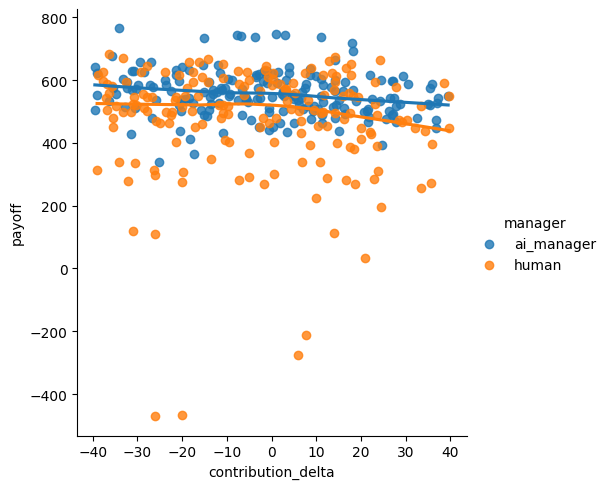

In [73]:
g = sns.lmplot(
    data=dfg[dfg["contribution_delta"] < 40][dfg["contribution_delta"] > -40],
    x="contribution_delta",
    y="payoff",
    hue="manager",
    scatter=True,
    lowess=True,
)

In the simulations, we had a local maximum for ai_governor around +6 contribution. This does not exist here anymore. In contrast, the relationship with contribution_delta and payoffs is actually more positive for human governor.

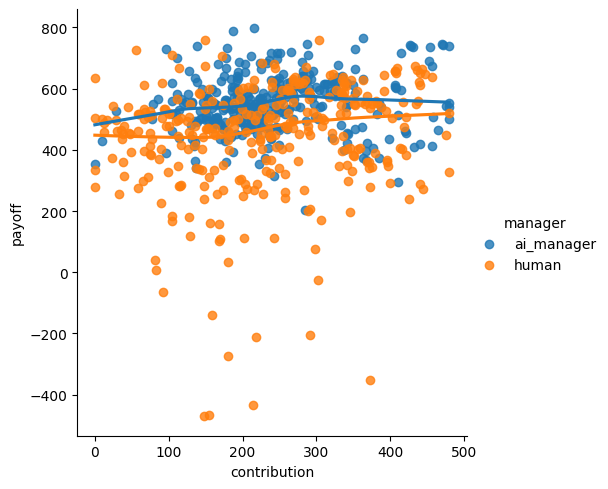

In [74]:
g = sns.lmplot(
    data=dfg,
    x="contribution",
    y="payoff",
    hue="manager",
    scatter=True,
    lowess=True,
)

In [75]:
dfr = dfe.copy()
dfr["contrib_rank"] = (
    dfr[["contributions", "round", "group_session", "groups", "manager"]]
    .groupby(["round", "group_session", "groups"])["contributions"]
    .rank(method="dense", ascending=False)
)
dfr["punish_with_tiebreaker"] = dfr["punishments"] + dfr["contrib_rank"] * 0.01

dfr["punish_rank"] = (
    dfr[["contributions", "round", "punish_with_tiebreaker", "group_session", "groups"]]
    .groupby(["round", "group_session", "groups"])["punish_with_tiebreaker"]
    .rank(method="dense")
)
dfr["is_fair"] = dfr["contrib_rank"] == dfr["punish_rank"]

dfr[
    [
        "participant_codes",
        "round",
        "contributions",
        "punishments",
        "contrib_rank",
        "punish_rank",
        "is_fair",
        "manager",
    ]
]

,participant_codes,round,contributions,punishments,contrib_rank,punish_rank,is_fair,manager
0,t34uu5qc,1,3,8,4.0,4.0,True,human
1,g286gj0i,1,8,2,2.0,2.0,True,human
2,yhvg4oxc,1,20,0,1.0,1.0,True,human
3,w7wup16f,1,4,7,3.0,3.0,True,human
4,t34uu5qc,2,9,4,2.0,2.0,True,human
...,...,...,...,...,...,...,...,...
15355,b8zoi006,23,8,0,1.0,1.0,True,ai_manager
15356,a3zzaz6d,24,1,0,3.0,3.0,True,ai_manager
15357,af3a644m,24,2,0,2.0,2.0,True,ai_manager
15358,3p1sbazq,24,0,0,4.0,4.0,True,ai_manager


In [76]:
dfrg = (
    dfr[["groups", "group_session", "is_fair", "manager"]]
    .groupby(["group_session", "groups", "manager"])
    .mean()
    .reset_index()
)

([0, 1], [Text(0, 0, 'ai_manager'), Text(1, 0, 'human')])

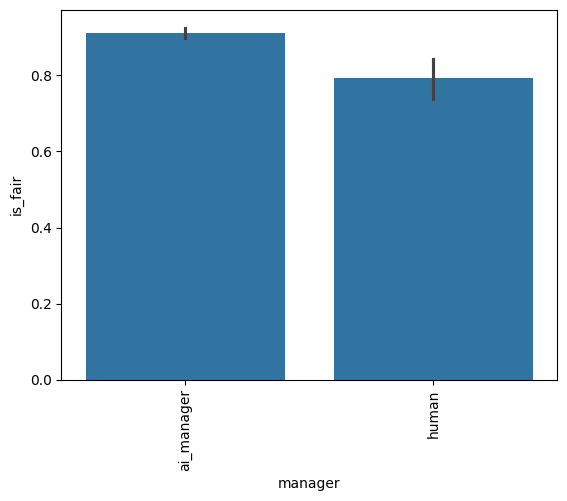

In [77]:
sns.barplot(data=dfrg, x="manager", y="is_fair")
plt.xticks(rotation=90)

<Axes: xlabel='groups', ylabel='is_fair'>

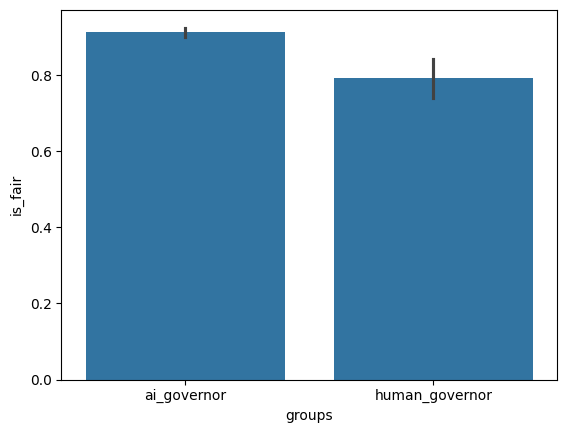

In [78]:
sns.barplot(data=dfrg, x="groups", y="is_fair")

8184 15360


([0, 1], [Text(0, 0, 'ai_manager'), Text(1, 0, 'human')])

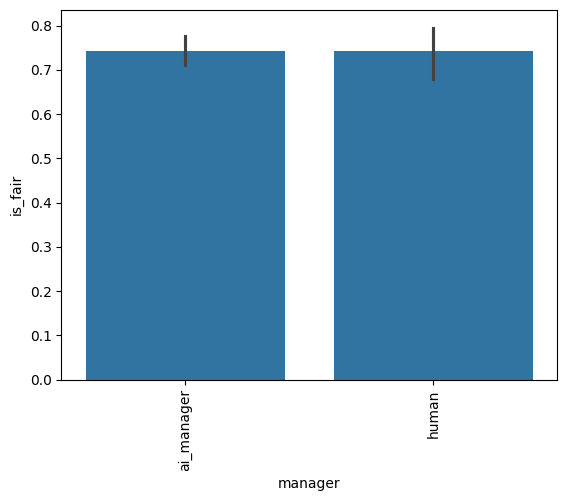

In [79]:
dfr_filtered = dfr[dfr["group_punishments"] > 0]
print(len(dfr_filtered), len(dfr))
dfrg_filtered = (
    dfr_filtered[["groups", "group_session", "is_fair", "manager"]]
    .groupby(["group_session", "groups", "manager"])
    .mean()
    .reset_index()
)
sns.barplot(data=dfrg_filtered, x="manager", y="is_fair")
plt.xticks(rotation=90)

<Axes: xlabel='groups', ylabel='is_fair'>

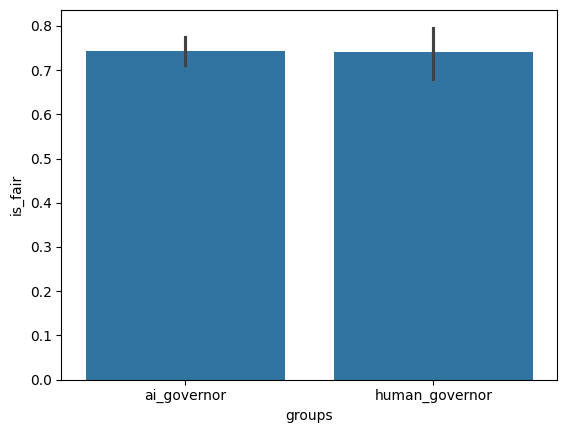

In [80]:
sns.barplot(data=dfrg_filtered, x="groups", y="is_fair")

In [81]:
# Fairness measure

dfu = dfr[dfr["groups"] == "ai_governor"]
(dfu["punish_rank"] == dfu["contrib_rank"]).mean()

np.float64(0.9122395833333333)

In [82]:
# Fairness measure

dfu = dfr[dfr["groups"] == "human_governor"]
(dfu["punish_rank"] == dfu["contrib_rank"]).mean()

np.float64(0.7920572916666667)

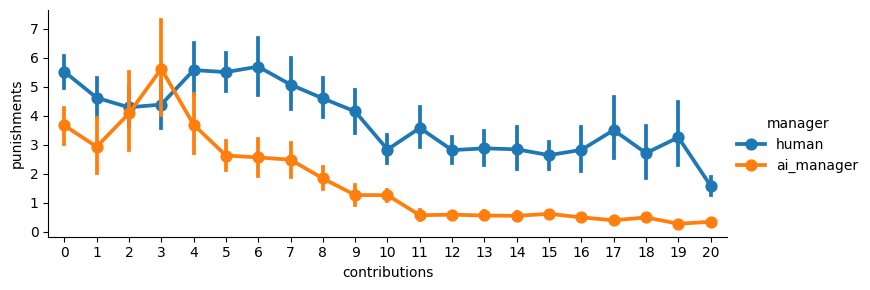

In [83]:
g = sns.catplot(
    data=dfe,
    x="contributions",
    y="punishments",
    hue="manager",
    kind="point",
    height=3,
    aspect=2.5,
)

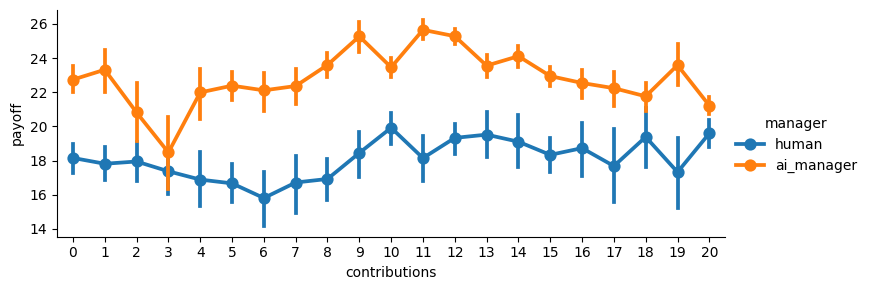

In [84]:
g = sns.catplot(
    data=dfe,
    x="contributions",
    y="payoff",
    hue="manager",
    kind="point",
    height=3,
    aspect=2.5,
)

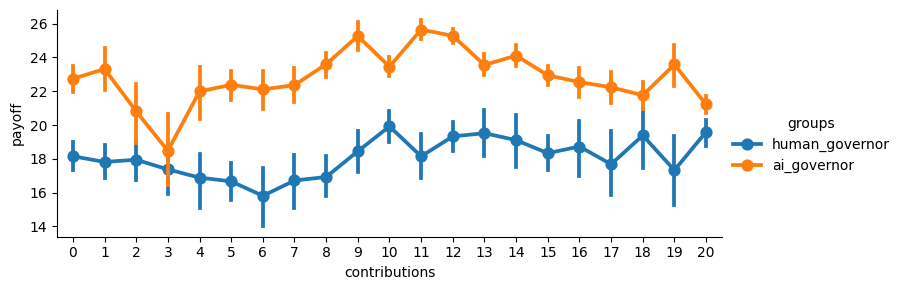

In [85]:
g = sns.catplot(
    data=dfe,
    x="contributions",
    y="payoff",
    hue="groups",
    kind="point",
    height=3,
    aspect=2.5,
)

In [86]:
for numeric in ["contributions", "punishments", "common_good", "payoff"]:
    dfe[numeric] = pd.to_numeric(dfe[numeric])

/tmp/ipykernel_26589/3302786788.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfe[numeric] = pd.to_numeric(dfe[numeric])


In [87]:
dfi = dfe[dfe["group_session"] == "ai_governor_ka5v3qsi4"]
dfi.groupby(["participant_codes"]).sum()

,index,id,revision_id,contributions,punishments,missing_inputs,missing_governor_input,groups,manager_code,manager_identity_transparent,...,common_good,payoff,contributions_mean,punishments_mean,common_good_mean,payoff_mean,contribution_delta,payoff_delta,punishment_delta,condition
participant_codes,,,,,,,,,,,,,,,,,,,,,


In [88]:
dfe[dfe["group_session"] == "ai_governor_ka5v3qsi4"][
    ["round", "contributions", "punishments", "participant_codes"]
]

,round,contributions,punishments,participant_codes


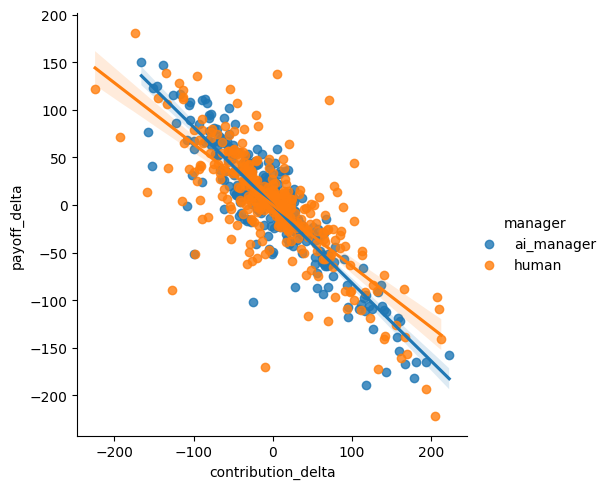

In [89]:
g = sns.lmplot(
    data=dfg,
    x="contribution_delta",
    y="payoff_delta",
    hue="manager",
    scatter=True,
    lowess=False,
)

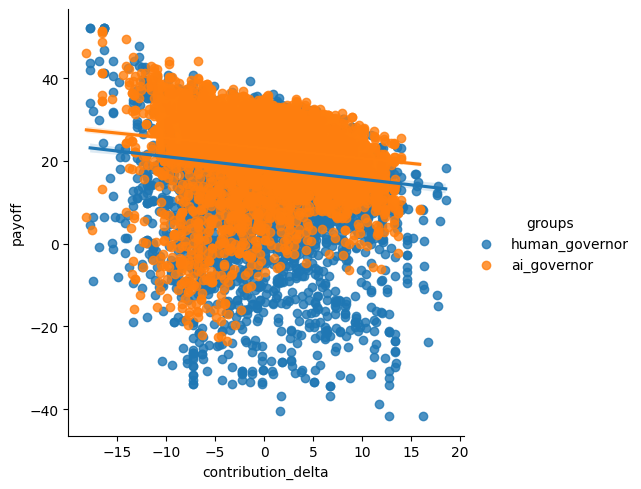

In [90]:
g = sns.lmplot(
    data=dfe,
    x="contribution_delta",
    y="payoff",
    hue="groups",
    scatter=True,
    lowess=False,
)

/tmp/ipykernel_26589/2020629800.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfe["contribution_delta_binned"] = contribution_delta_binned


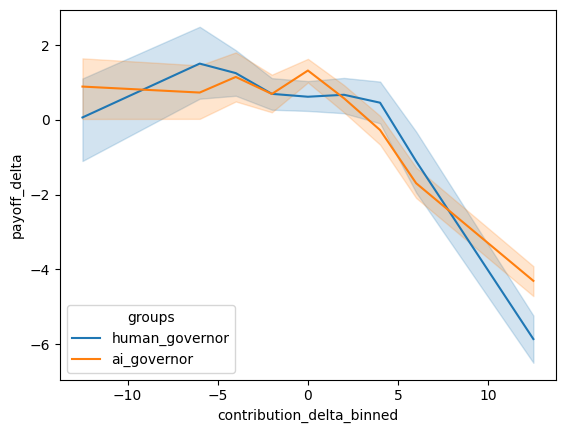

In [91]:
contribution_delta_binned = pd.cut(
    dfe["contribution_delta"], bins=[-18] + list(np.arange(-7, 8, 2)) + [18]
)
contribution_delta_binned = contribution_delta_binned.apply(lambda x: x.mid).astype(
    float
)
dfe["contribution_delta_binned"] = contribution_delta_binned

g = sns.lineplot(
    data=dfe,
    x="contribution_delta_binned",
    y="payoff_delta",
    hue="groups",
)

/tmp/ipykernel_26589/2290396479.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfe["contribution_delta_binned"] = contribution_delta_binned


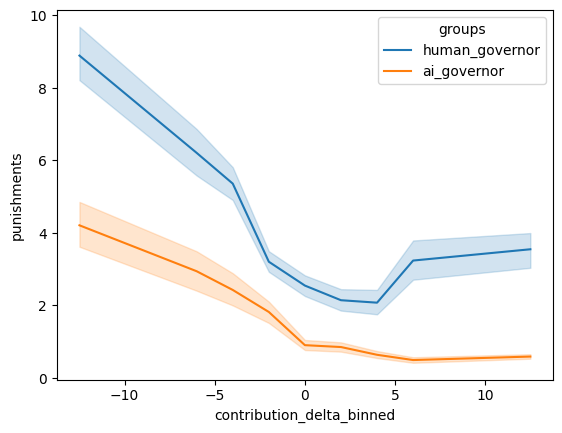

In [92]:
contribution_delta_binned = pd.cut(
    dfe["contribution_delta"], bins=[-18] + list(np.arange(-7, 8, 2)) + [18]
)
contribution_delta_binned = contribution_delta_binned.apply(lambda x: x.mid).astype(
    float
)
dfe["contribution_delta_binned"] = contribution_delta_binned

g = sns.lineplot(
    data=dfe,
    x="contribution_delta_binned",
    y="punishments",
    hue="groups",
)

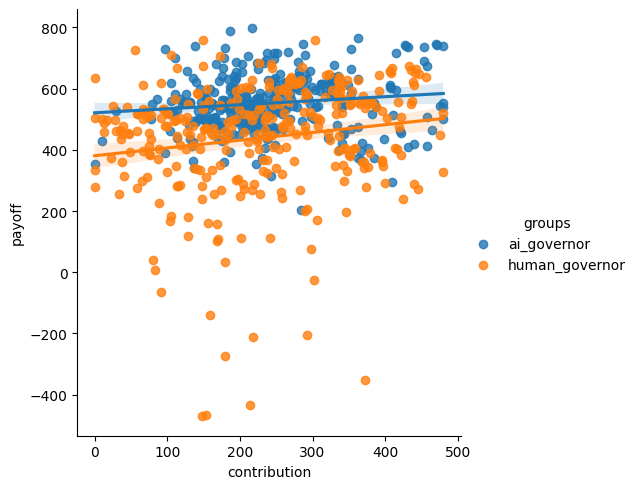

In [93]:
g = sns.lmplot(
    data=dfg,
    x="contribution",
    y="payoff",
    hue="groups",
    scatter=True,
    lowess=False,
)

In [94]:
for group in dfg["group_session"].unique():
    dff = dfg[dfg["group_session"] == group]
    slope, intercept, r_value, p_value, std_err = stats.linregress(
        dff["contribution"], dff["punishment_delta"]
    )
    print(f"{group}: {slope=}, {intercept=}, {r_value=}, {p_value=}")

ai_governor_2iu7mws912: slope=np.float64(-0.7816291161178509), intercept=np.float64(138.3483535528596), r_value=np.float64(-0.6677865969854517), p_value=np.float64(0.33221340301454827)
ai_governor_2iu7mws92: slope=np.float64(-0.3781027477169409), intercept=np.float64(75.80960091724666), r_value=np.float64(-0.6479285569542996), p_value=np.float64(0.35207144304570037)
ai_governor_2iu7mws95: slope=np.float64(-0.8399209486166008), intercept=np.float64(154.96541501976284), r_value=np.float64(-0.9079259644902761), p_value=np.float64(0.09207403550972391)
ai_governor_2iu7mws96: slope=np.float64(0.14128742909906344), intercept=np.float64(-41.89172272787231), r_value=np.float64(0.6221658396539034), p_value=np.float64(0.3778341603460966)
ai_governor_2iu7mws98: slope=np.float64(-0.3056530214424951), intercept=np.float64(56.316569200779725), r_value=np.float64(-0.7077449716097399), p_value=np.float64(0.2922550283902599)
ai_governor_2iu7mws99: slope=np.float64(-0.715775637464694), intercept=np.float

(array([-5.,  0.,  5., 10., 15., 20., 25., 30.]),
 [Text(-5.0, 0, '−5'),
  Text(0.0, 0, '0'),
  Text(5.0, 0, '5'),
  Text(10.0, 0, '10'),
  Text(15.0, 0, '15'),
  Text(20.0, 0, '20'),
  Text(25.0, 0, '25'),
  Text(30.0, 0, '30')])

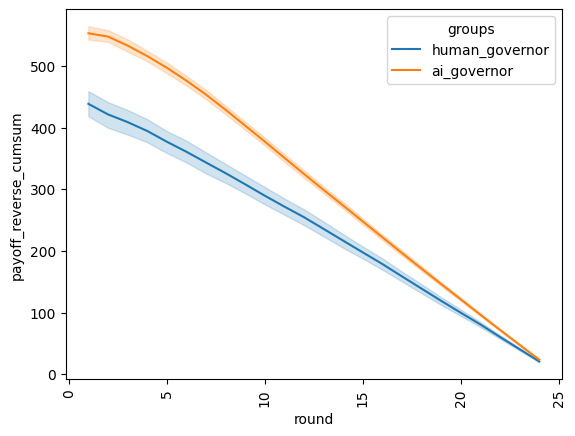

In [95]:
df_reverse = dfe.sort_values(
    ["group_session", "participant_codes", "round"], ascending=False
).reset_index(drop=True)
df_reverse["payoff_reverse_cumsum"] = df_reverse.groupby(
    ["group_session", "participant_codes"]
)[["payoff"]].cumsum()
sns.lineplot(data=df_reverse, x="round", y="payoff_reverse_cumsum", hue="groups")
plt.xticks(rotation=90)

<Axes: xlabel='round', ylabel='payoff_cumsum'>

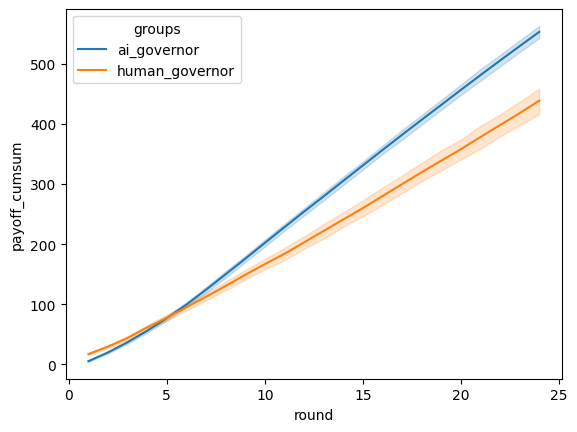

In [96]:
df_sorted = dfe.sort_values(
    ["group_session", "participant_codes", "round"], ascending=True
).reset_index(drop=True)
df_sorted["payoff_cumsum"] = df_sorted.groupby(["group_session", "participant_codes"])[
    ["payoff"]
].cumsum()
sns.lineplot(data=df_sorted, x="round", y="payoff_cumsum", hue="groups")